# 02 · CODEX colorectal cancer: my cell-type annotation

**Data:** CODEX multiplexed imaging of the colorectal cancer invasive front (Schürch et al., *Cell* 2020).
There are 35 patients, each with 4 regions (140 regions in total), and 56 protein markers per cell.
The patients fall into two groups: **CLR** (Crohn's-like reaction, with tertiary lymphoid structures)
and **DII** (diffuse inflammatory infiltration).

**Steps** (the same workflow as notebook 01, adapted to protein intensities)

1. Load the marker intensities, coordinates and patient metadata into one `AnnData`.
2. Quality control: remove likely debris.
3. Normalize: arcsinh transform, per-region background correction, then scale.
4. PCA on lineage markers, kNN graph, UMAP.
5. Leiden clustering, with the resolution chosen by marker coherence.
6. Marker evidence for each cluster.
7. My cluster → cell-type dictionary.
8. Spatial check (region maps, neighborhood enrichment). Save.

The authors' labels (`ClusterName`, neighborhoods) are **not** loaded here. They enter only in notebook 04.

## Parameters
All tunable values in one place. The random seed is fixed.

In [1]:
from pathlib import Path

DATA_FILE   = Path("data/codex_crc/CRC_clusters_neighborhoods_markers.csv")
RESULTS_DIR = Path("results")
FIG_DIR     = RESULTS_DIR / "figures"

COFACTOR    = 150     # arcsinh cofactor for fluorescence intensities
BRIGHT_PCT  = 95      # QC: a marker is bright above this percentile
MAX_BRIGHT  = 20      # QC: remove cells bright in >= this many markers
NUC_PCT     = 1       # QC: remove cells below this HOECHST percentile
BG_PCT      = 25      # per-region background percentile; validate sensitivity
N_PCS       = 20
N_NEIGHBORS = 15
RESOLUTIONS = [0.4, 0.6, 0.8, 1.0, 1.2, 1.5]
N_TOP       = 3
LOW_SIGNAL  = 0.6     # low signal if median total corrected arcsinh < this x overall median
MIN_COHER   = 0.75    # heuristic cluster-coherence threshold (SD units)
RESOLUTION  = None    # chosen by the coherence rule in section 5 (set a value only to override it)
SEED        = 0

# Lineage markers define cell identity; functional markers remain for description.
LINEAGE = ["CD45", "CD3", "CD4", "CD8", "FOXP3", "CD45RO", "CD45RA", "CD2", "CD7",
           "Granzyme B", "CD56", "CD20", "CD21", "HLA-DR", "CD38", "CD138",
           "CD68", "CD163", "CD11b", "CD11c", "CD15",
           "Cytokeratin", "MUC-1", "CDX2", "beta-catenin",
           "aSMA", "Vimentin", "Podoplanin", "Collagen IV", "CD31", "CD34",
           "GFAP", "Synaptophysin", "Chromogranin A"]


In [2]:
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

# Do not suppress all warnings globally: dependency/data warnings are useful during review.
sc.settings.verbosity = 1
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)


In [3]:
# record the software versions of this run (a fixed seed alone does not guarantee identical results across versions)
import sys
from importlib.metadata import version
print("python", sys.version.split()[0])
print({p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "scanpy", "anndata",
                                "squidpy", "igraph", "leidenalg", "matplotlib"]})

python 3.13.17
{'numpy': '2.4.6', 'pandas': '3.0.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'scanpy': '1.12.4', 'anndata': '0.13.4', 'squidpy': '1.8.3', 'igraph': '1.0.0', 'leidenalg': '0.12.0', 'matplotlib': '3.11.2'}


## 1 · Load the data

The CSV has one row per cell. The columns used here are:

- **Marker intensities:** columns containing `:Cyc_`. Nuclear stains (HOECHST, DRAQ5) are kept aside for QC only, and empty or blank channels are dropped.
- **Coordinates:** `X:X` and `Y:Y`, in pixels. These are **per region**: every region has its own frame starting at 0.
- **Metadata:** `patients`, `groups` (1 = CLR, 2 = DII), and the region (`File Name`) and cell size.

The authors' cell-type and neighborhood columns are deliberately not read.

In [4]:
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Input file not found: {DATA_FILE.resolve()}\n"
        "Run this notebook from the project root or update DATA_FILE."
    )
raw = pd.read_csv(DATA_FILE)

required = {"CellID", "patients", "groups", "File Name", "size:size", "X:X", "Y:Y"}
missing = sorted(required.difference(raw.columns))
if missing:
    raise ValueError(f"Input CSV is missing required metadata columns: {missing}")

cyc = [c for c in raw.columns if ":Cyc_" in c]
nuclear = [c for c in cyc if any(s in c.upper() for s in ["HOECHST", "DRAQ5"])]
markers = [c for c in cyc if c not in nuclear and not any(s in c.upper() for s in ["EMPTY", "BLANK"])]
if not nuclear:
    raise ValueError("No HOECHST/DRAQ5 nuclear-stain channel was found for QC.")
if not markers:
    raise ValueError("No marker-intensity columns were found (expected columns containing ':Cyc_').")
short = [c.split(" - ")[0].split(":")[0] for c in markers]
if len(short) != len(set(short)):
    dupes = pd.Index(short)[pd.Index(short).duplicated()].unique().tolist()
    raise ValueError(f"Marker names are not unique after shortening: {dupes}. Resolve channel names explicitly.")
if not set(LINEAGE).issubset(short):
    raise ValueError(f"Expected lineage markers absent from input: {sorted(set(LINEAGE) - set(short))}")

print(f"{len(markers)} markers, {len(nuclear)} nuclear stains, {len(raw):,} cells")

# Metadata only; author cell-type and neighborhood labels are deliberately excluded.
group_map = {1: "CLR", 2: "DII", "1": "CLR", "2": "DII"}
group_values = raw["groups"].map(group_map)
if group_values.isna().any():
    unknown = raw.loc[group_values.isna(), "groups"].astype(str).unique().tolist()
    raise ValueError(f"Unexpected values in 'groups': {unknown}; expected 1=CLR and 2=DII.")

obs = pd.DataFrame({
    "cell_id": raw["CellID"].astype(str).values,
    "patient": raw["patients"].astype(str).values,
    "group": group_values.values,
    "region": raw["File Name"].astype(str).values,
    "size": pd.to_numeric(raw["size:size"], errors="coerce").values,
    "nuclear": pd.to_numeric(raw[nuclear[0]], errors="coerce").values,
})
if obs["cell_id"].duplicated().any():
    raise ValueError("CellID values are not unique; use a unique cell index before constructing AnnData.")
if obs[["size", "nuclear"]].isna().any().any():
    raise ValueError("Cell size or nuclear stain contains non-numeric/missing values; inspect the input CSV.")
obs.index = obs["cell_id"]

adata = ad.AnnData(raw[markers].apply(pd.to_numeric, errors="coerce").to_numpy(dtype="float32"), obs=obs)
if not np.isfinite(adata.X).all():
    raise ValueError("Marker intensities contain missing or non-finite values; resolve them before normalization.")
adata.var_names = short
adata.obsm["spatial"] = raw[["X:X", "Y:Y"]].to_numpy(dtype="float32")
for c in ["patient", "group", "region"]:
    adata.obs[c] = adata.obs[c].astype("category")
del raw

print(adata.obs.groupby("group", observed=True)["patient"].nunique().rename("patients"))
adata


56 markers, 2 nuclear stains, 258,385 cells


group
CLR    17
DII    18
Name: patients, dtype: int64


AnnData object with n_obs × n_vars = 258385 × 56
    obs: 'cell_id', 'patient', 'group', 'region', 'size', 'nuclear'
    obsm: 'spatial'
    layers: None (.X)

## 2 · Quality control

The authors' segmentation has already removed very small objects, so the size and nuclear-stain
distributions show no separate debris mode. Two simple rules remove what is left:

- **Weak nuclear stain.** A real cell has a nucleus. Cells below the `NUC_PCT` percentile of HOECHST signal are dropped.
- **Pan-bright objects.** A real cell is bright in a few lineage markers. Autofluorescent debris is bright in
  many unrelated channels at once. Cells above the `BRIGHT_PCT` percentile in at least `MAX_BRIGHT` markers are dropped.

Anything that survives but carries no clear identity will show up as its own cluster and be named `unknown`.

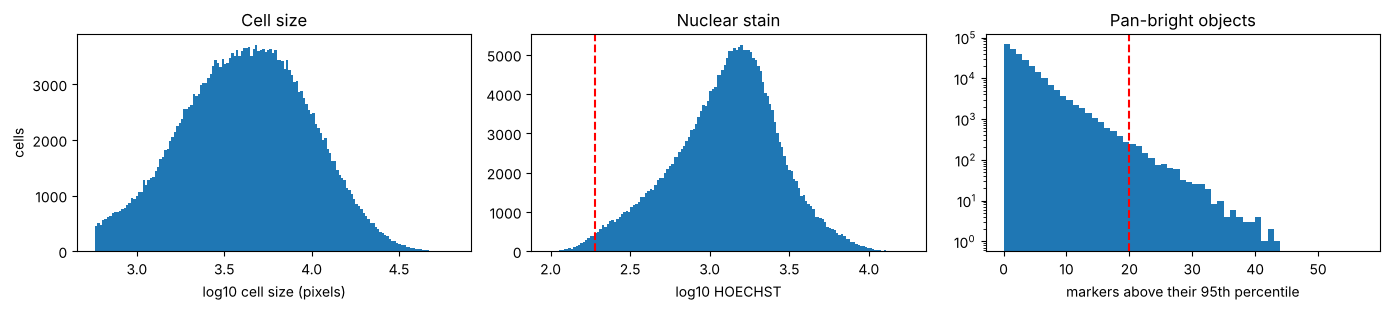

In [5]:
X_asinh = np.arcsinh(adata.X / COFACTOR)                        # transform first (QC uses it too)
n_bright = (X_asinh > np.percentile(X_asinh, BRIGHT_PCT, axis=0)).sum(axis=1)
nuc_cut = np.percentile(adata.obs["nuclear"], NUC_PCT)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].hist(np.log10(adata.obs["size"]), bins=150)
ax[0].set(xlabel="log10 cell size (pixels)", ylabel="cells", title="Cell size")
ax[1].hist(np.log10(adata.obs["nuclear"] + 1), bins=150)
ax[1].axvline(np.log10(nuc_cut + 1), color="red", ls="--")
ax[1].set(xlabel="log10 HOECHST", title="Nuclear stain")
ax[2].hist(n_bright, bins=np.arange(58), log=True)
ax[2].axvline(MAX_BRIGHT, color="red", ls="--")
ax[2].set(xlabel=f"markers above their {BRIGHT_PCT}th percentile", title="Pan-bright objects")
plt.tight_layout(); plt.show()

In [6]:
keep = (adata.obs["nuclear"].to_numpy() >= nuc_cut) & (n_bright < MAX_BRIGHT)
print(f"weak nucleus: {(adata.obs['nuclear'] < nuc_cut).sum():,}   pan-bright: {(n_bright >= MAX_BRIGHT).sum():,}")
adata = adata[keep].copy()
X_asinh = X_asinh[keep]
print(f"kept {adata.n_obs:,} of {len(keep):,} cells")

weak nucleus: 2,584   pan-bright: 1,172
kept 254,639 of 258,385 cells


## 3 · Normalize

1. **arcsinh(x / cofactor).** This is close to linear near zero and logarithmic for bright signal. It compresses
   the long tails of fluorescence intensities, like log1p does for counts.
2. **Per-region background correction.** Imaging conditions differ between regions (staining, focus,
   autofluorescence), which shifts every marker up or down by region. For each region and marker, the `BG_PCT`-th
   percentile is subtracted and the result is clipped at 0. A low percentile is used because for any
   marker most cells in a region are negative, so this percentile is background, not signal.
3. **Scale** each marker to zero mean and unit variance (clipped at 10).

The check below shows how much of each principal component is explained by the region (R², between-region variance
divided by total variance) before and after the correction.

In [7]:
def region_r2(pcs, region):
    """Approximate fraction of each PC's variance attributable to region means."""
    df = pd.DataFrame(pcs)
    region_means = df.groupby(region.to_numpy(), observed=True).transform("mean")
    return (region_means.var(ddof=1) / df.var(ddof=1)).to_numpy()

lin = np.isin(adata.var_names, LINEAGE)
region = adata.obs["region"]

def quick_pcs(X):
    # Standardize marker columns before a compact SVD; U contains PC score directions.
    X = np.asarray(X, dtype=np.float32)
    sd = X.std(axis=0, ddof=0)
    sd[sd == 0] = 1.0
    Z = (X - X.mean(axis=0)) / sd
    return np.linalg.svd(Z - Z.mean(axis=0), full_matrices=False)[0][:, :5]

r2_before = region_r2(quick_pcs(X_asinh[:, lin]), region)

# Per-region background correction. This is a modeling assumption, not proof that all
# removed regional signal is technical; compare marker distributions before/after.
X_bg = X_asinh.copy()
for r in region.cat.categories:
    m = (region == r).to_numpy()
    X_bg[m] = np.clip(X_bg[m] - np.percentile(X_bg[m], BG_PCT, axis=0), 0, None)

r2_after = region_r2(quick_pcs(X_bg[:, lin]), region)
pd.DataFrame({"before": r2_before, "after": r2_after},
             index=[f"PC{i}" for i in range(1, 6)]).round(3).T.rename_axis("region R²")


,PC1,PC2,PC3,PC4,PC5
region R²,,,,,
before,0.290,0.233,0.353,0.271,0.196
after,0.092,0.159,0.114,0.152,0.076


In [8]:
adata.X = X_bg
adata.layers["asinh"] = X_bg.copy()              # background-corrected arcsinh, for plots
sc.pp.scale(adata, max_value=10)                 # .X is now scaled
del X_bg            # X_asinh is kept for the background-correction sensitivity analysis (section 7c)

## 4 · PCA (lineage markers), neighbor graph, UMAP

The PCA uses only the lineage markers (`mask_var="lineage"`). The elbow guides `N_PCS`.

34 lineage markers used for PCA


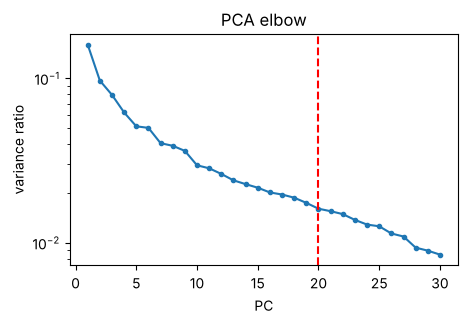

first 20 PCs explain 85.8% of the lineage-marker variance


In [9]:
adata.var["lineage"] = np.isin(adata.var_names, LINEAGE)
print(f"{adata.var['lineage'].sum()} lineage markers used for PCA")

sc.tl.pca(adata, n_comps=30, mask_var="lineage", random_state=SEED)
vr = adata.uns["pca"]["variance_ratio"]
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.arange(1, 31), vr, "o-", ms=3)
ax.axvline(N_PCS, color="red", ls="--")
ax.set(xlabel="PC", ylabel="variance ratio", yscale="log", title="PCA elbow")
plt.show()
print(f"first {N_PCS} PCs explain {vr[:N_PCS].sum():.1%} of the lineage-marker variance")

In [10]:
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 5 · Leiden clustering and the choice of resolution

This is the same idea as notebook 01. With intensities instead of counts, "fraction of cells detecting a gene"
is replaced by the **standardized mean difference**. For cluster $k$ and its top `N_TOP` lineage markers (t-test):

$$s_k = \frac{1}{N_{\text{top}}}\sum_{g} \big(\,\bar z_{g,\,\text{in } k} - \bar z_{g,\,\text{out of } k}\big)$$

Here $z$ is the scaled intensity, so $s_k$ is in standard-deviation units.

**Low-signal clusters.** A cluster whose cells are dim in all markers (median total signal below `LOW_SIGNAL` × the overall median)
has no real markers, so it is reported separately and not allowed to drive the choice.

In [11]:
# Total signal is computed from corrected arcsinh values before per-marker scaling.
total_signal = np.asarray(adata.layers["asinh"].sum(axis=1)).ravel()
Z = adata.X


def cluster_summary(adata, key, n_top=N_TOP):
    """Cluster size, median total signal, heuristic coherence, and top lineage markers."""
    sub = adata[:, adata.var["lineage"].to_numpy()].copy()
    sc.tl.rank_genes_groups(sub, key, method="t-test", use_raw=False)
    labels = adata.obs[key].astype(str).to_numpy()
    rows = []
    for k in adata.obs[key].cat.categories.astype(str):
        top = list(sub.uns["rank_genes_groups"]["names"][k][:n_top])
        idx = [adata.var_names.get_loc(g) for g in top]
        inside = labels == k
        outside = ~inside
        # A descriptive separation score; cells are not independent biological replicates.
        s = float((Z[inside][:, idx].mean(axis=0) - Z[outside][:, idx].mean(axis=0)).mean())
        rows.append({"cluster": k, "n_cells": int(inside.sum()),
                     "median_signal": float(np.median(total_signal[inside])),
                     "coherence": s, "top_markers": " ".join(top)})
    return pd.DataFrame(rows).set_index("cluster")

low_cut = LOW_SIGNAL * np.median(total_signal)
rows, summaries = [], {}
for r in RESOLUTIONS:
    key = f"leiden_{r}"
    sc.tl.leiden(adata, resolution=r, key_added=key, flavor="igraph",
                 n_iterations=2, directed=False, random_state=SEED)
    s = cluster_summary(adata, key)
    summaries[r] = s
    ok = s[s["median_signal"] >= low_cut]
    rows.append({"resolution": r, "n_clusters": len(s), "n_low_signal": len(s) - len(ok),
                 "min_coherence": ok["coherence"].min() if len(ok) else np.nan,
                 "median_coherence": ok["coherence"].median() if len(ok) else np.nan})

scan = pd.DataFrame(rows).set_index("resolution")
scan["ARI_to_next"] = [adjusted_rand_score(adata.obs[f"leiden_{a}"], adata.obs[f"leiden_{b}"])
                       for a, b in zip(RESOLUTIONS[:-1], RESOLUTIONS[1:])] + [np.nan]
scan.round(3)


/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: 

/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: 

/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: 

/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: 

/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: 

/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/usr/local/lib/python3.13/site-packages/scanpy/tools/_rank_genes_groups.py:633: 

,n_clusters,n_low_signal,min_coherence,median_coherence,ARI_to_next
resolution,,,,,
0.4,14,2,1.075,1.777,0.771
0.6,18,1,0.729,1.952,0.714
0.8,20,1,0.487,1.958,0.674
1.0,24,2,0.871,1.919,0.762
1.2,25,3,0.602,1.915,0.727
1.5,30,5,0.436,1.887,NaN


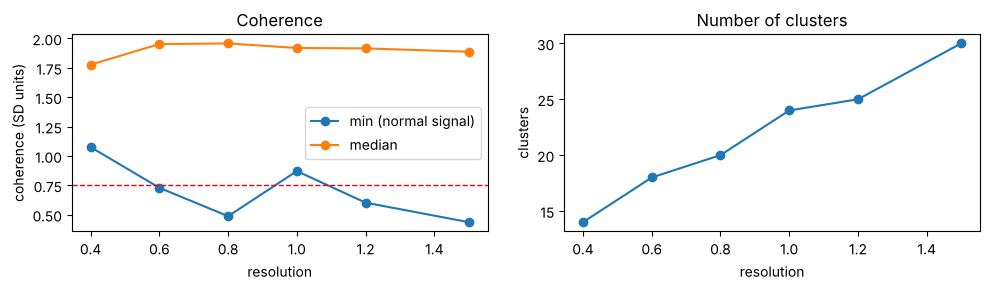

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(scan.index, scan["min_coherence"], "o-", label="min (normal signal)")
ax[0].plot(scan.index, scan["median_coherence"], "o-", label="median")
ax[0].axhline(MIN_COHER, color="red", ls="--", lw=1)
ax[0].set(xlabel="resolution", ylabel="coherence (SD units)", title="Coherence"); ax[0].legend()
ax[1].plot(scan.index, scan["n_clusters"], "o-")
ax[1].set(xlabel="resolution", ylabel="clusters", title="Number of clusters")
plt.tight_layout(); plt.show()

In [13]:
# which normal-signal clusters fall below the threshold at each resolution?
for r, s in summaries.items():
    weak = s[(s["median_signal"] >= low_cut) & (s["coherence"] < MIN_COHER)]
    print(f"resolution {r}: " + ("all pass" if weak.empty else
          "; ".join(f"cl {k} ({row.top_markers}, signal {row.median_signal:.1f}, s={row.coherence:.2f})"
                    for k, row in weak.iterrows())))
print(f"low-signal cut: {low_cut:.1f}")

resolution 0.4: all pass
resolution 0.6: cl 4 (aSMA Podoplanin Collagen IV, signal 12.3, s=0.73)
resolution 0.8: cl 0 (beta-catenin CDX2 CD11b, signal 12.5, s=0.49)
resolution 1.0: all pass
resolution 1.2: cl 12 (CDX2 beta-catenin CD11b, signal 13.7, s=0.60)
resolution 1.5: cl 1 (CD11c CD11b CD68, signal 12.4, s=0.44); cl 2 (CDX2 beta-catenin CD11b, signal 14.0, s=0.71)
low-signal cut: 12.0



**Choice of resolution.**

- **Rule:** the same as in notebook 01. Take the highest tested resolution at which every cluster above the low-signal cut has coherence of at least `MIN_COHER`. The code below applies it.
- **Result:** in this run the rule selects **1.0**. Resolutions 0.6, 0.8, 1.2 and 1.5 each contain at least one normal-signal cluster below the threshold, as listed above.
- **The rule is sensitive to one group of cells.** At 0.8 and 1.2 the failing cluster is the same dim group (and one of the two at 1.5) with weak CDX2/beta-catenin. Its median signal sits just above or below the low-signal cut, depending on how Leiden draws its boundary. The choice of resolution therefore depends on `LOW_SIGNAL` as much as on the biology, and this dim group is labeled `unknown` below.
- **Cluster numbers are not stable identifiers.** Leiden IDs change with the resolution, the library versions or the preprocessing. The annotation below is written for the clusters of this run and is protected by the key-marker check.

The coherence statistic is a heuristic computed on the same cells it describes. It is not independent validation of cell identity.


In [14]:
# apply the rule: highest resolution whose normal-signal clusters all reach MIN_COHER
passing = [r for r, s in summaries.items()
           if not ((s["median_signal"] >= low_cut) & (s["coherence"] < MIN_COHER)).any()]
if not passing:
    raise ValueError("No tested resolution passes the coherence rule; review the scan and set RESOLUTION manually.")
rule_resolution = max(passing)
if RESOLUTION is None:
    RESOLUTION = rule_resolution
elif RESOLUTION != rule_resolution:
    print(f"NOTE: manual override {RESOLUTION}; the rule selects {rule_resolution}.")
if RESOLUTION not in summaries:
    raise ValueError(f"RESOLUTION={RESOLUTION} is not in RESOLUTIONS={RESOLUTIONS}.")
print(f"passing resolutions: {passing}; selected: {RESOLUTION}")
KEY = f"leiden_{RESOLUTION}"
adata.obs["cluster"] = adata.obs[KEY].astype("category")
summary = summaries[RESOLUTION].copy()
summary["low_signal"] = summary["median_signal"] < low_cut

# Region/group concentration are diagnostic flags, not automatic evidence of artifact.
summary["top_region_frac"] = [
    adata.obs.loc[adata.obs["cluster"].astype(str) == str(k), "region"].value_counts(normalize=True).iloc[0]
    for k in summary.index
]
summary["frac_CLR"] = [
    (adata.obs.loc[adata.obs["cluster"].astype(str) == str(k), "group"] == "CLR").mean()
    for k in summary.index
]
summary.round(2)


passing resolutions: [0.4, 1.0]; selected: 1.0


,n_cells,median_signal,coherence,top_markers,low_signal,top_region_frac,frac_CLR
cluster,,,,,,,
0,16947,10.87,0.29,beta-catenin CDX2 CD11b,True,0.06,0.43
1,8253,3.84,-0.53,CD163 CD11c CD68,True,0.03,0.50
2,9596,12.28,0.96,aSMA CD56 Collagen IV,False,0.05,0.40
3,12059,24.49,2.33,CD11b CD15 CD56,False,0.05,0.24
4,880,29.94,1.32,CD8 FOXP3 CD4,False,0.50,0.28
5,22894,14.09,0.87,aSMA Podoplanin Vimentin,False,0.03,0.35
6,16627,22.02,1.56,CD38 CDX2 beta-catenin,False,0.04,0.48
7,17471,17.32,1.24,CD68 CD163 CD11c,False,0.03,0.39
8,17440,21.26,1.28,CD3 CD4 CD45RO,False,0.04,0.45


**How much does the selected resolution depend on the two thresholds?** `LOW_SIGNAL` and `MIN_COHER` are analyst-defined operational values,
not biological cutoffs. The grid below re-applies the rule for nearby values (no re-clustering needed, only the scan above).

In [15]:
def rule_pick(low_signal, min_coher):
    cut = low_signal * np.median(total_signal)
    ok = [r for r, s in summaries.items() if not ((s["median_signal"] >= cut) & (s["coherence"] < min_coher)).any()]
    return max(ok) if ok else np.nan

grid = pd.DataFrame({mc: {ls: rule_pick(ls, mc) for ls in [0.4, 0.5, 0.6, 0.7, 0.8]} for mc in [0.5, 0.75, 1.0]})
grid.index.name, grid.columns.name = "LOW_SIGNAL", "MIN_COHER"
grid

MIN_COHER,0.50,0.75,1.00
LOW_SIGNAL,,,
0.4,1.2,NaN,NaN
0.5,1.2,NaN,NaN
0.6,1.2,1.0,0.4
0.7,1.5,1.5,1.5
0.8,1.5,1.5,1.5


**Result.** Across this grid the selected resolution moves between 0.4 and 1.5, and under the strictest settings no resolution passes.
Resolution 1.0 is chosen only at the default pair. The clustering granularity is therefore not robust to these two thresholds,
and the annotation dictionary below is tied to one point of this grid.

Read the grid as the honest uncertainty of the resolution choice: where neighbouring settings pick a different resolution, the clustering
granularity, and with it the annotation dictionary, would change.

## 6 · Marker evidence for each cluster

- **Heatmap:** the mean background-corrected intensity of each lineage marker per cluster, scaled 0–1 per marker. This is the main naming evidence.
- **Table:** the mean scaled intensity (SD units) of the same markers. It is useful when two clusters look alike in the heatmap.
- **Functional markers** (Ki67, PD-1, ICOS, ...) are shown separately. They describe the state of a cell, not its type.

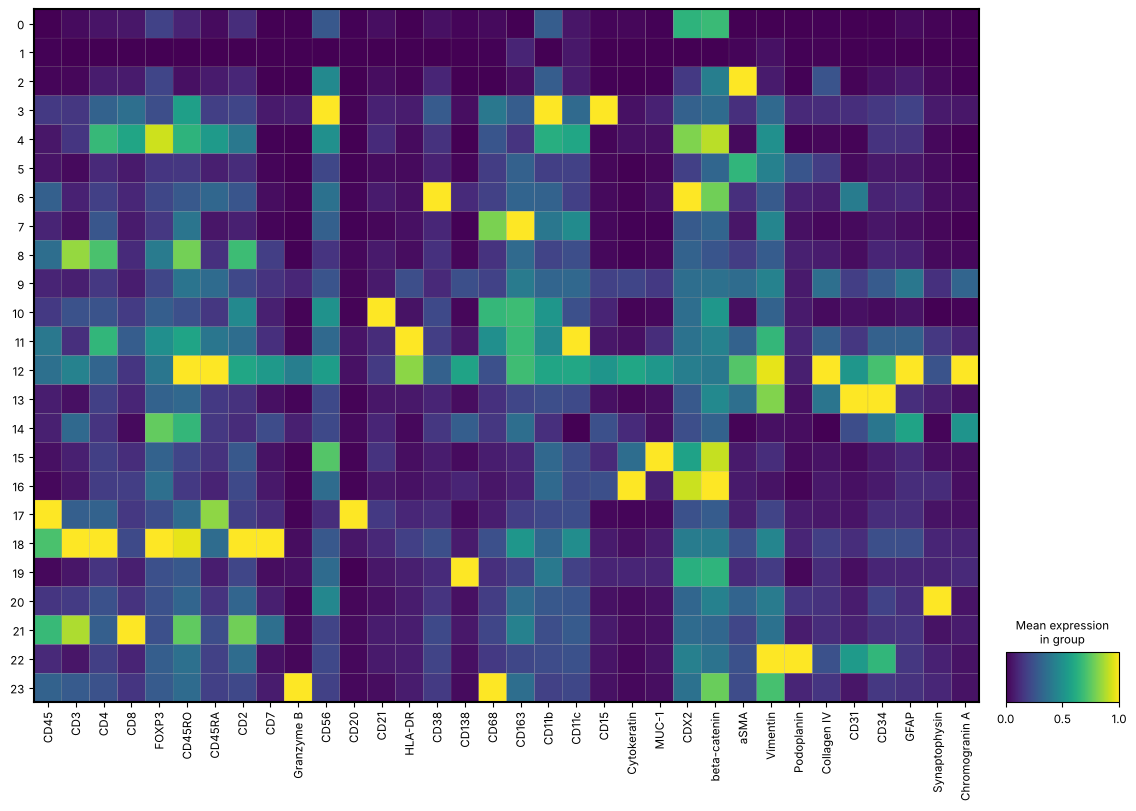

In [16]:
lineage_order = ["CD45", "CD3", "CD4", "CD8", "FOXP3", "CD45RO", "CD45RA", "CD2", "CD7",
                 "Granzyme B", "CD56", "CD20", "CD21", "HLA-DR", "CD38", "CD138",
                 "CD68", "CD163", "CD11b", "CD11c", "CD15",
                 "Cytokeratin", "MUC-1", "CDX2", "beta-catenin",
                 "aSMA", "Vimentin", "Podoplanin", "Collagen IV", "CD31", "CD34",
                 "GFAP", "Synaptophysin", "Chromogranin A"]
mp = sc.pl.matrixplot(adata, lineage_order, groupby="cluster", layer="asinh", standard_scale="var",
                      cmap="viridis", figsize=(14, 9), show=False, return_fig=True)
mp.savefig(FIG_DIR / "codex_lineage_matrixplot.png", dpi=120)
plt.show()

In [17]:
# Aggregate once by cluster to avoid retaining unnecessary intermediate copies.
zmean = pd.DataFrame(adata.X, columns=adata.var_names, index=adata.obs_names).groupby(
    adata.obs["cluster"].astype(str), observed=True
).mean()
zmean.to_csv(RESULTS_DIR / "codex_cluster_mean_z.csv")
with pd.option_context("display.max_columns", 40):
    display(zmean.reindex(columns=lineage_order).T.round(1).style.background_gradient(
        cmap="RdBu_r", vmin=-3, vmax=3, axis=None
    ).format("{:.1f}"))


cluster,0,1,10,11,12,13,14,15,16,17,18,19,2,20,21,22,23,3,4,5,6,7,8,9
CD45,-0.6,-0.6,-0.2,0.4,0.3,-0.4,-0.4,-0.5,-0.5,1.8,1.1,-0.5,-0.5,-0.2,1.0,-0.3,0.2,-0.2,-0.4,-0.5,0.1,-0.3,0.3,-0.3
CD3,-0.5,-0.6,0.0,-0.3,0.5,-0.5,0.3,-0.4,-0.4,0.2,1.9,-0.4,-0.5,-0.2,1.6,-0.4,0.1,-0.2,-0.2,-0.5,-0.4,-0.5,1.5,-0.4
CD4,-0.6,-0.7,-0.0,1.1,0.1,-0.2,-0.3,-0.2,-0.2,0.1,2.0,-0.3,-0.5,-0.1,0.1,-0.2,-0.0,0.1,1.1,-0.4,-0.2,-0.0,1.2,-0.3
CD8,-0.4,-0.6,-0.0,0.3,-0.1,-0.2,-0.5,-0.2,-0.0,-0.1,0.1,-0.3,-0.3,-0.1,2.5,-0.3,-0.1,0.6,1.3,-0.4,-0.2,-0.4,-0.2,-0.3
FOXP3,-0.2,-0.7,0.0,0.5,0.3,0.1,1.2,0.1,0.2,-0.1,1.8,-0.1,-0.2,-0.1,-0.1,0.0,0.0,-0.1,1.6,-0.3,-0.2,-0.3,0.3,-0.2
CD45RO,-0.6,-0.8,-0.3,0.4,1.3,-0.1,0.6,-0.4,-0.4,-0.1,1.2,-0.2,-0.7,-0.1,0.8,-0.0,-0.1,0.4,0.6,-0.5,-0.2,0.0,0.9,0.0
CD45RA,-0.6,-0.7,-0.2,0.5,2.4,-0.2,-0.2,-0.2,-0.4,1.9,0.4,-0.4,-0.5,-0.2,0.0,-0.1,-0.1,-0.1,1.0,-0.4,0.3,-0.5,-0.2,0.4
CD2,-0.4,-0.6,0.4,0.1,0.6,-0.3,-0.4,-0.1,-0.2,-0.2,1.5,-0.2,-0.4,0.1,1.1,0.1,-0.2,-0.2,0.2,-0.4,-0.1,-0.5,0.8,-0.2
CD7,-0.4,-0.4,-0.1,0.0,1.4,-0.3,0.3,-0.2,-0.2,-0.0,2.9,-0.3,-0.4,-0.1,0.8,-0.3,-0.2,-0.2,-0.4,-0.4,-0.3,-0.4,0.2,0.1
Granzyme B,-0.3,-0.3,-0.2,-0.1,4.2,-0.2,0.6,-0.2,-0.2,-0.2,0.0,0.2,-0.3,-0.1,0.0,-0.1,8.2,0.6,-0.3,-0.3,-0.2,-0.3,-0.2,0.9


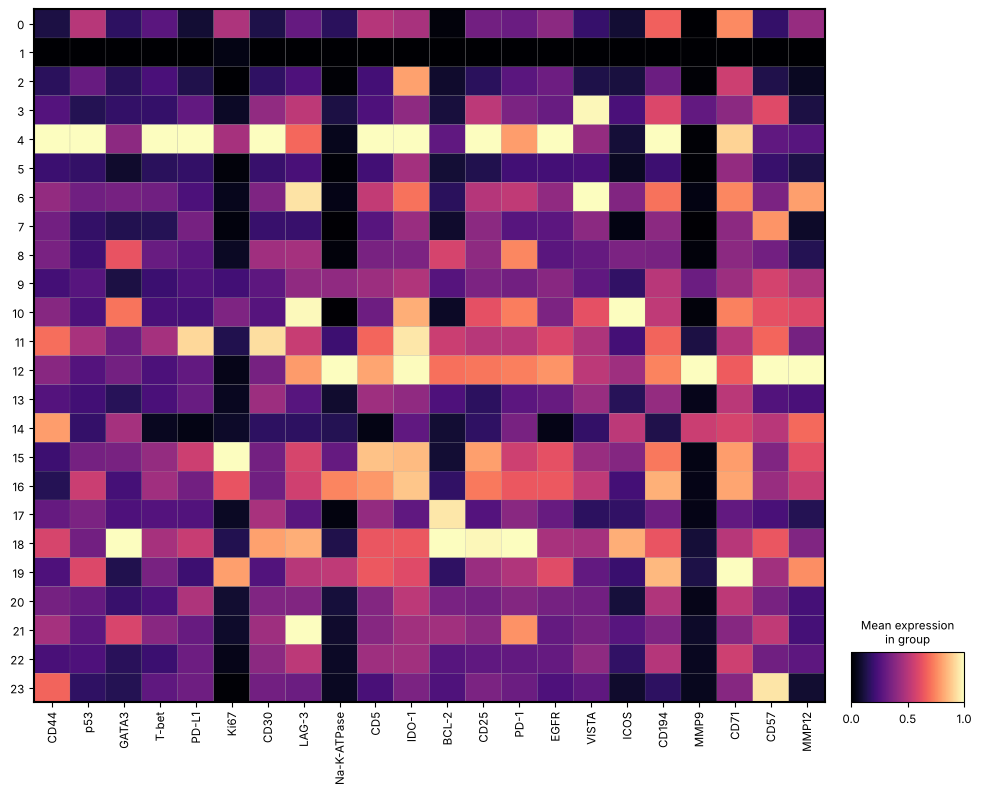

In [18]:
functional = [m for m in adata.var_names if m not in LINEAGE]
sc.pl.matrixplot(adata, functional, groupby="cluster", layer="asinh", standard_scale="var",
                 cmap="magma", figsize=(12, 9))

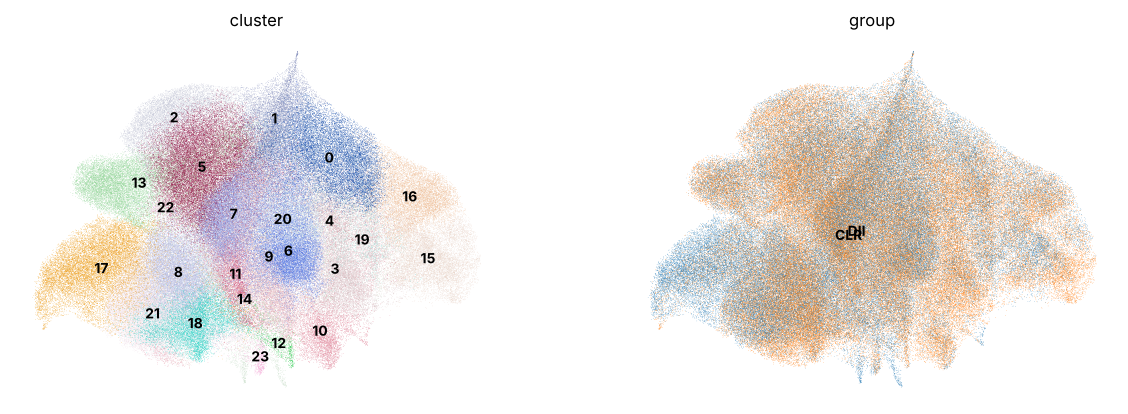

In [19]:
sc.pl.umap(adata, color=["cluster", "group"], legend_loc="on data", size=0.5, frameon=False, ncols=2)

## Save the clustered data

This file can be used to restart from the clusters without rerunning sections 1–5. `.X` holds the background-corrected arcsinh values
(the scaled matrix is not stored; the PCA stays in `.obsm["X_pca"]`).

In [20]:
adata.X = adata.layers.pop("asinh")
adata.write_h5ad(RESULTS_DIR / "codex_clustered.h5ad", compression="gzip")
adata

AnnData object with n_obs × n_vars = 254639 × 56
    obs: 'cell_id', 'patient', 'group', 'region', 'size', 'nuclear', 'leiden_0.4', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0', 'leiden_1.2', 'leiden_1.5', 'cluster'
    var: 'mean', 'std', 'lineage'
    uns: 'pca', 'neighbors', 'umap', 'leiden_0.4', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0', 'leiden_1.2', 'leiden_1.5', 'cluster_colors', 'group_colors'
    obsm: 'spatial', 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X)


## 7 · My annotation

Labels below are a **provisional, manually reviewed interpretation** of the cluster marker profiles at the selected resolution.
The rule is conservative: a cluster with **low signal, weak coherence or conflicting lineage markers** is labeled `unknown`
rather than forced into a cell type. Region enrichment and spatial patterns are supporting context, not standalone proof of identity.

This is stricter than the first version of this notebook. Five clusters that version named, all marked there as needing a check, are now `unknown`:
- the dim CDX2+ group,
- the CD21-high "follicular DCs",
- the CD38-high "plasma cells",
- the CD138+ cells,
- the Granzyme B+ cells.

**Note for the comparison in notebook 04.** This revision was made after the first comparison with the authors' labels had been seen.
The rule itself uses only the evidence in this notebook (marker conflicts flagged in the first version). Still, agreement statistics
computed with the revised labels are no longer fully blind, and notebook 04 should say so.

Leiden cluster numbers can change with resolution, Scanpy/igraph versions or preprocessing. The checks below stop the notebook if the mapping no longer fits.


In [21]:
# Cluster -> (provisional label, key marker), for the clusters selected above.
# Evidence = mean z of lineage markers (table in section 6). Uncertain profiles are unknown.
annotation = {
    # --- epithelial / tumor ---
    "16": ("Tumor cells",             "Cytokeratin"),   # Cytokeratin, beta-catenin, CDX2
    "15": ("Tumor cells MUC-1+",      "MUC-1"),         # MUC-1, Cytokeratin, beta-catenin
    "0":  ("unknown", None),          # dim overall (at the low-signal cut), only weak CDX2/beta-catenin: do not force as tumor
    # --- stroma ---
    "2":  ("Smooth muscle",           "aSMA"),          # aSMA (high), Collagen IV
    "5":  ("Stroma",                  "Podoplanin"),    # aSMA, Podoplanin, Vimentin
    "13": ("Vasculature",             "CD31"),          # CD34, CD31, Vimentin, Collagen IV
    "22": ("Lymphatics",              "Podoplanin"),    # Podoplanin (very high), CD34, CD31
    "14": ("Nerves",                  "GFAP"),          # GFAP, Chromogranin A, CD138; provisional neural-like profile
    # --- lymphoid ---
    "8":  ("CD4+ T cells",            "CD3"),           # CD3, CD4, CD45RO
    "18": ("Tregs",                   "FOXP3"),         # CD3, CD4, CD7, FOXP3, ICOS; verify against activated CD4 cells
    "21": ("CD8+ T cells",            "CD8"),           # CD8, CD3, CD45, CD45RO
    "17": ("B cells",                 "CD20"),          # CD20, CD45, CD45RA
    # --- myeloid ---
    "7":  ("Macrophages CD68+CD163+", "CD68"),          # CD68, CD163, CD11c
    "11": ("CD11c+ myeloid cells",    "HLA-DR"),        # HLA-DR (very high), CD11c, CD4
    "3":  ("Granulocytes",            "CD15"),          # CD15 (high), CD56, CD11b
    # --- unclear: conflicting lineage markers ---
    "10": ("unknown", None),          # CD21 high without CD20, with CD68/CD163: FDC identity not established
    "6":  ("unknown", None),          # CD38 high with CDX2/beta-catenin: plasma cell vs. epithelial ambiguity
    "19": ("unknown", None),          # CD138 high with CDX2/beta-catenin: plasma cell vs. epithelial ambiguity
    "23": ("unknown", None),          # Granzyme B with CD68, no CD3/CD56: lineage unclear
    # --- unclear: no lineage signature ---
    "1":  ("unknown", None),          # low signal in every marker
    "9":  ("unknown", None),          # moderate signal in many unrelated markers
    "12": ("unknown", None),          # bright in nearly every channel: likely debris
    "20": ("unknown", None),          # Synaptophysin only, no lineage partner
    "4":  ("unknown", None),          # mixed FOXP3, CD8, CD4, beta-catenin, CDX2; half from one region
}

observed_clusters = set(adata.obs["cluster"].cat.categories.astype(str))
if set(annotation) != observed_clusters:
    missing_labels = sorted(observed_clusters - set(annotation))
    extra_labels = sorted(set(annotation) - observed_clusters)
    raise ValueError(
        "Annotation mapping does not match the selected clustering. "
        f"Clusters without labels: {missing_labels}; labels for absent clusters: {extra_labels}. "
        "Review the marker table and update annotation; do not bypass this check."
    )

# Validate key markers against the actual per-cluster mean-z table.
top5 = zmean.reindex(columns=lineage_order).apply(lambda row: list(row.nlargest(5).index), axis=1)
bad = {
    k: (name, key, top5.get(k, []))
    for k, (name, key) in annotation.items()
    if key and (k not in top5.index or key not in top5[k])
}
if bad:
    raise ValueError(f"Some labels are not supported by their cluster's top-5 mean markers: {bad}. Review labels.")

adata.obs["cell_type"] = adata.obs["cluster"].astype(str).map(
    {k: v[0] for k, v in annotation.items()}
).astype("category")
print("Cluster labels validated against current cluster IDs and key markers.")
adata.obs["cell_type"].value_counts().to_frame("n_cells")

Cluster labels validated against current cluster IDs and key markers.


,n_cells
cell_type,
unknown,84691
Stroma,22894
B cells,17861
CD8+ T cells,17646
Macrophages CD68+CD163+,17471
CD4+ T cells,17440
Vasculature,17329
Granulocytes,12059
Tumor cells MUC-1+,10560


A fixed color per cell type, shared by every plot in this notebook and reused in notebooks 03–04.

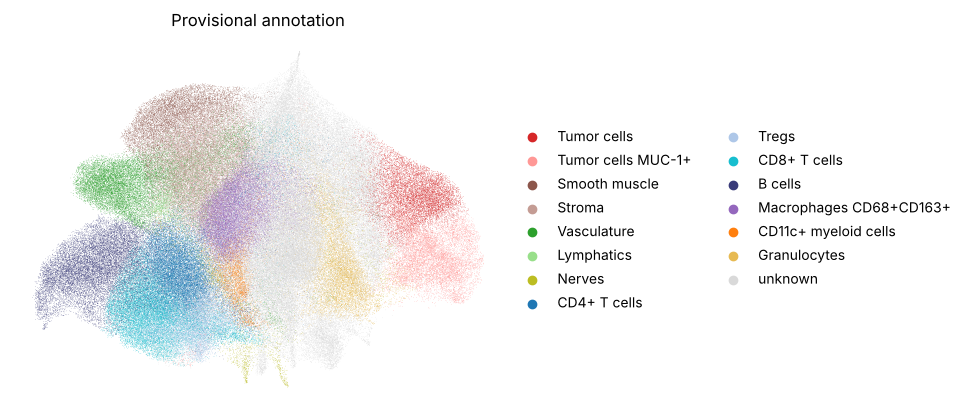

In [22]:
palette = {
    "Tumor cells": "#d62728", "Tumor cells MUC-1+": "#ff9896",
    "Smooth muscle": "#8c564b", "Stroma": "#c49c94", "Vasculature": "#2ca02c", "Lymphatics": "#98df8a",
    "Nerves": "#bcbd22",
    "CD4+ T cells": "#1f77b4", "Tregs": "#aec7e8", "CD8+ T cells": "#17becf", "B cells": "#393b79",
    "Follicular DCs": "#9edae5", "Plasma cells": "#6b6ecf", "CD138+ cells": "#c5b0d5",
    "Macrophages CD68+CD163+": "#9467bd", "CD11c+ myeloid cells": "#ff7f0e",
    "Granulocytes": "#e7ba52", "Granzyme B+ cells": "#e377c2", "unknown": "#d9d9d9",
}
unknown_names = set(adata.obs["cell_type"].cat.categories) - set(palette)
if unknown_names:
    raise ValueError(f"Labels without a color: {sorted(unknown_names)}")
order = [c for c in palette if c in set(adata.obs["cell_type"])]   # only types present in this annotation
adata.obs["cell_type"] = adata.obs["cell_type"].cat.reorder_categories(order)
adata.uns["cell_type_colors"] = [palette[c] for c in order]

sc.pl.umap(adata, color="cell_type", size=0.5, frameon=False, title="Provisional annotation")


### 7b · Where do the `unknown` cells come from?

A high `unknown` share can mean a careful annotation, but also insufficient marker coverage, preprocessing problems or an overly strict rule.
It is not, by itself, evidence of quality. The tables break it down by original cluster, signal level, patient and region.

In [23]:
unk = (adata.obs["cell_type"] == "unknown").to_numpy()
by_cluster = (pd.DataFrame({"cluster": adata.obs["cluster"].astype(str).to_numpy(), "unknown": unk})
              .groupby("cluster")["unknown"].agg(["size", "mean"]))
by_cluster = by_cluster[by_cluster["mean"] > 0].rename(columns={"size": "n_cells", "mean": "share unknown"})
by_cluster["reason (from the annotation comments)"] = by_cluster.index.map(lambda k: "" if k not in annotation else
    {"0": "dim, weak CDX2/beta-catenin", "10": "CD21 high, no CD20", "6": "CD38 high + epithelial signal",
     "19": "CD138 high + epithelial signal", "23": "Granzyme B + CD68, no T/NK", "1": "low signal",
     "9": "many unrelated markers", "12": "bright everywhere", "20": "Synaptophysin only",
     "4": "mixed lineages"}.get(k, ""))
print(f"unknown: {unk.sum():,} cells ({unk.mean():.1%})")
display(by_cluster.sort_values("n_cells", ascending=False))

q = pd.qcut(total_signal, 5, labels=["lowest", "low", "middle", "high", "highest"])
print("share unknown by total-signal quintile:")
print((pd.Series(unk).groupby(q.to_numpy(), observed=True).mean() * 100).round(1).to_string())

pat = pd.Series(unk).groupby(adata.obs["patient"].astype(str).to_numpy()).mean() * 100
grp = adata.obs.groupby("patient", observed=True)["group"].first()
grp.index = grp.index.astype(str)
print("\nshare unknown per patient: median {:.1f}%, range {:.1f}–{:.1f}%".format(pat.median(), pat.min(), pat.max()))
print("median by group:", (pat.groupby(grp.reindex(pat.index).to_numpy()).median()).round(1).to_dict())
reg = pd.Series(unk).groupby(adata.obs["region"].astype(str).to_numpy()).mean() * 100
print("share unknown per region: median {:.1f}%, 10th–90th percentile {:.1f}–{:.1f}%".format(reg.median(), reg.quantile(.1), reg.quantile(.9)))

unknown: 84,691 cells (33.3%)


,n_cells,share unknown,reason (from the annotation comments)
cluster,,,
9,21784,1.0,many unrelated markers
0,16947,1.0,"dim, weak CDX2/beta-catenin"
6,16627,1.0,CD38 high + epithelial signal
20,9486,1.0,Synaptophysin only
1,8253,1.0,low signal
10,6367,1.0,"CD21 high, no CD20"
19,2750,1.0,CD138 high + epithelial signal
4,880,1.0,mixed lineages
12,839,1.0,bright everywhere


share unknown by total-signal quintile:
high       29.9
highest    29.2
low        30.5
lowest     47.2
middle     29.5

share unknown per patient: median 35.2%, range 15.6–59.7%
median by group: {'CLR': 34.8, 'DII': 35.7}
share unknown per region: median 33.5%, 10th–90th percentile 12.9–57.6%


**Result.**
- **A cluster-level decision:** every `unknown` cell comes from a cluster named `unknown` as a whole, so this label is decided for clusters, not cells.
- **By signal:** `unknown` is much more common among the dimmest fifth of cells (47%, against about 30% in the other quintiles).
- **By patient and region:** the share varies widely (16–60% per patient, 13–58% for the middle 80% of regions), but is similar in CLR and DII (median 35% vs. 36%).

Patient-level comparisons in notebook 04 therefore rest on different fractions of each patient's cells.

### 7c · Sensitivity to the background correction

The per-region correction subtracts the 25th percentile of each marker and clips at zero. It can remove technical shifts but also real biology,
and clipping changes the distribution of dim signals. The pipeline is repeated (correction → scale → lineage PCA → kNN → Leiden at the selected resolution)
for three alternatives: **no correction**, the **10th** and the **50th** percentile. For each, the ARI with the main clustering and, as in notebook 01,
the share of cells whose label survives (majority label of their new cluster).

In [24]:
def recluster(X):
    b = ad.AnnData(X.copy()); b.var_names = adata.var_names
    b.var["lineage"] = adata.var["lineage"].to_numpy()
    sc.pp.scale(b, max_value=10)
    sc.tl.pca(b, n_comps=N_PCS, mask_var="lineage", random_state=SEED)
    sc.pp.neighbors(b, n_neighbors=N_NEIGHBORS, n_pcs=N_PCS, random_state=SEED)
    sc.tl.leiden(b, resolution=RESOLUTION, key_added="leiden", flavor="igraph", n_iterations=2, directed=False, random_state=SEED)
    return b.obs["leiden"].to_numpy()

def bg_correct(X, pct):
    if pct is None:
        return X.copy()
    out = X.copy()
    for r in adata.obs["region"].cat.categories:
        m = (adata.obs["region"] == r).to_numpy()
        out[m] = np.clip(out[m] - np.percentile(out[m], pct, axis=0), 0, None)
    return out

labels_now = adata.obs["cell_type"].astype(str).to_numpy()
rows = []
for name, pct in [("no correction", None), ("10th percentile", 10), ("50th percentile", 50)]:
    cl = recluster(bg_correct(X_asinh, pct))
    major = pd.crosstab(cl, labels_now).idxmax(axis=1)
    same = pd.Series(cl).map(major).to_numpy() == labels_now
    named = labels_now != "unknown"
    rows.append({"background correction": name, "clusters": len(set(cl)),
                 "ARI with main clustering": round(adjusted_rand_score(adata.obs["cluster"], cl), 3),
                 "labels unchanged, all cells %": round(100 * same.mean(), 1),
                 "labels unchanged, named cells %": round(100 * same[named].mean(), 1)})
del X_asinh
pd.DataFrame(rows).set_index("background correction")

,clusters,ARI with main clustering,"labels unchanged, all cells %","labels unchanged, named cells %"
background correction,,,,
no correction,29,0.498,74.1,70.5
10th percentile,23,0.546,76.9,72.0
50th percentile,37,0.524,75.9,71.6


**Result.** The background correction matters a great deal.
- **Clustering:** with no correction, the 10th or the 50th percentile, the ARI with the main clustering is only 0.50–0.55.
- **Labels:** 70–72% of named cells keep their label (74–77% of all cells).
- **Compared with Xenium:** the CODEX annotation depends on this preprocessing choice much more than the Xenium annotation depends on its normalization (86% of cells stable).

Conclusions that rest on specific CODEX labels inherit this uncertainty. A per-type breakdown of this sensitivity was not computed here.

**Check of the naming:** the lineage heatmap grouped by cell type.

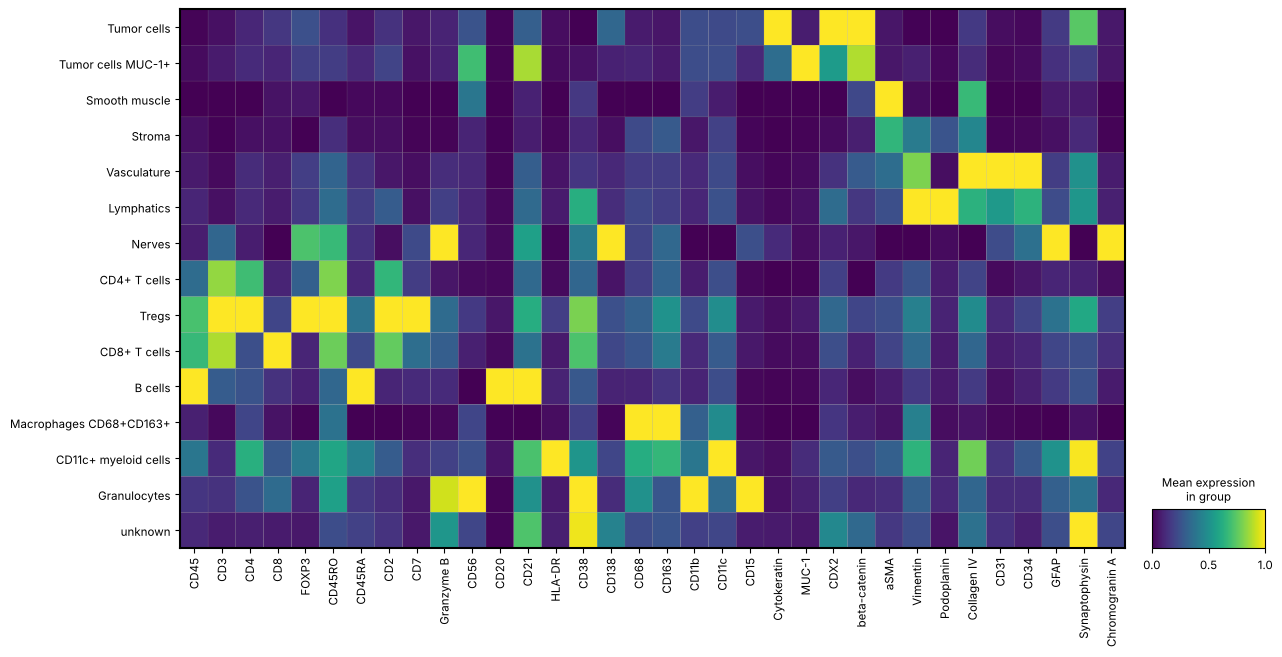

In [25]:
mp = sc.pl.matrixplot(adata, lineage_order, groupby="cell_type", standard_scale="var",
                      cmap="viridis", figsize=(14, 7), show=False, return_fig=True)
mp.savefig(FIG_DIR / "codex_celltype_matrixplot.png", dpi=120)
plt.show()

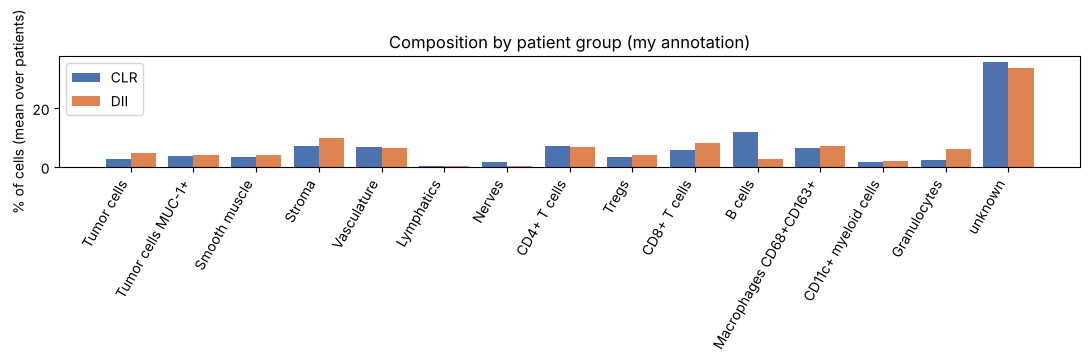

In [26]:
# composition per patient group: fraction of each type per patient, then averaged over the patients of a group
per_patient = pd.crosstab(adata.obs["patient"], adata.obs["cell_type"], normalize="index")
patient_group = adata.obs.groupby("patient", observed=True)["group"].first()
comp = per_patient.groupby(patient_group.reindex(per_patient.index).values).mean().T.reindex(order) * 100
fig, ax = plt.subplots(figsize=(11, 3.5))
w = 0.4
x = np.arange(len(order))
ax.bar(x - w / 2, comp["CLR"], w, label="CLR", color="#4c72b0")
ax.bar(x + w / 2, comp["DII"], w, label="DII", color="#dd8452")
ax.set_xticks(x, order, rotation=60, ha="right")
ax.set(ylabel="% of cells (mean over patients)", title="Composition by patient group (my annotation)"); ax.legend()
plt.tight_layout(); plt.show()


## 8 · Spatial check

Each region has its own coordinate frame, so spatial analysis is run **within regions**:

1. Maps of two large regions from each patient group.
2. Neighborhood enrichment with a radius of `NEIGH_RADIUS_UM` µm.

**Graph.** The graph is built separately per region (`library_key="region"`), so there are no edges between regions.

**Null model.** `squidpy.gr.nhood_enrichment` permutes labels across *all* cells. With 140 regions of very different composition, that null
mixes two effects: cells being neighbors, and cell types simply occurring in the same regions (for example, B cells and T cells both enriched in CLR patients).
Here the labels are permuted **within each region** instead, which keeps every region's composition fixed. The z-score then measures only the
local arrangement inside regions. The squidpy (global-permutation) z-scores are computed too, for comparison.

These cell-level z-scores are descriptive, not patient-level inferential tests. Neighborhood enrichment is evidence of spatial association, not of causal interaction or cell identity.


In [27]:
import squidpy as sq

PIXEL_UM        = 0.377          # µm per pixel
NEIGH_RADIUS_UM = 30             # µm, spatial neighbor radius
N_PERMS         = 200

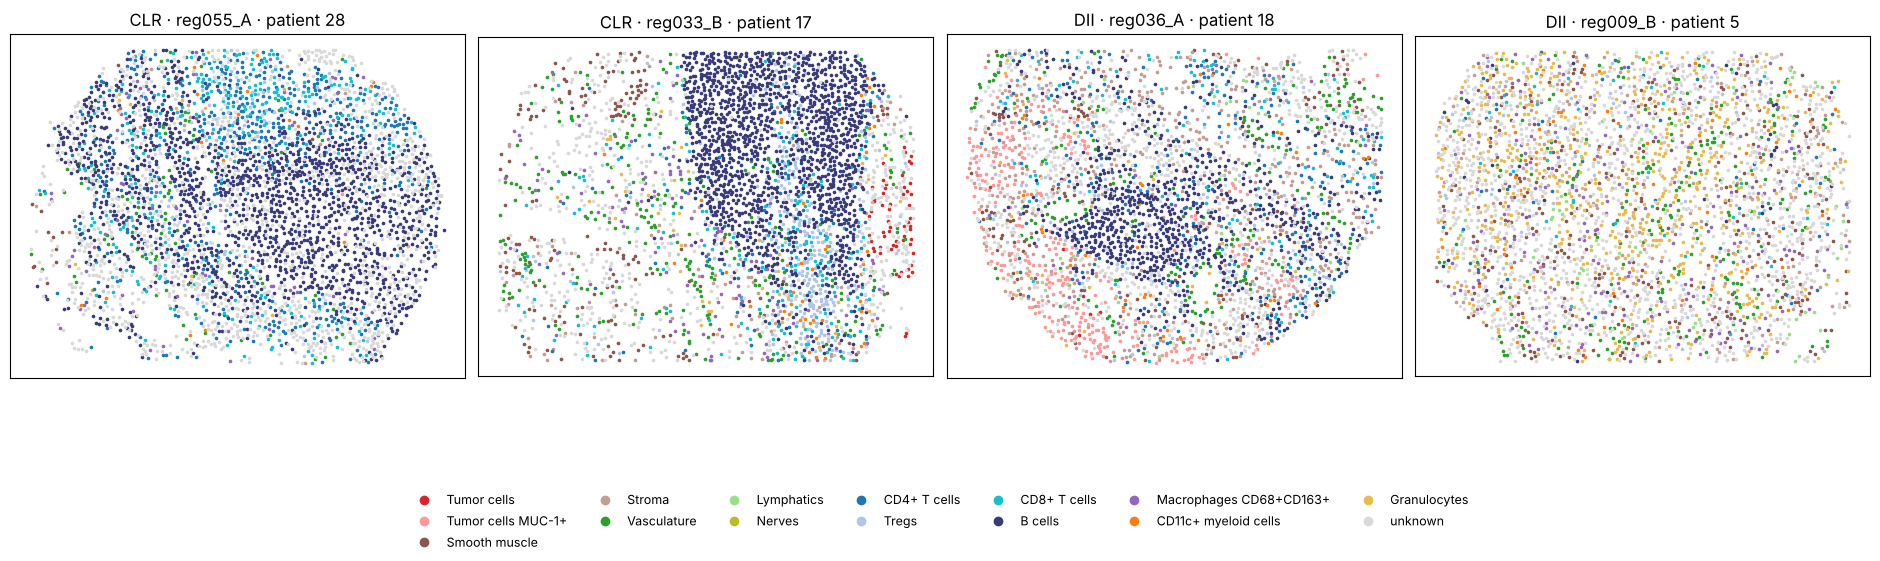

In [28]:
def plot_types(ax, xy, labels, title, s=7):
    # scatter cells colored by cell type, image orientation (y down)
    for c in order:
        m = labels == c
        if m.any():
            ax.scatter(xy[m, 0], xy[m, 1], s=s, c=palette[c], rasterized=True, linewidths=0)
    ax.set_aspect("equal"); ax.invert_yaxis()
    ax.set(title=title, xticks=[], yticks=[])

# the two largest regions of each group
sizes = adata.obs.groupby(["group", "region"], observed=True).size().rename("n").reset_index()
show = sizes.sort_values("n", ascending=False).groupby("group", observed=True).head(2).sort_values("group")

fig, axes = plt.subplots(1, 4, figsize=(24, 6.5))
for ax, (_, row) in zip(axes, show.iterrows()):
    m = (adata.obs["region"] == row["region"]).to_numpy()
    plot_types(ax, adata.obsm["spatial"][m] * PIXEL_UM, adata.obs["cell_type"].to_numpy()[m],
               f"{row['group']} · {row['region']} · patient {adata.obs['patient'][m].iloc[0]}")
handles = [plt.Line2D([], [], marker="o", ls="", color=palette[c], label=c) for c in order]
fig.legend(handles=handles, loc="lower center", ncol=7, fontsize=9, frameon=False)
plt.subplots_adjust(bottom=0.2, wspace=0.03)
plt.savefig(FIG_DIR / "codex_celltype_regions.png", dpi=120)
plt.show()

In [29]:
# coordinates in µm for the spatial graph
adata.obsm["spatial_um"] = adata.obsm["spatial"] * PIXEL_UM
sq.gr.spatial_neighbors(adata, spatial_key="spatial_um", library_key="region",
                        coord_type="generic", radius=NEIGH_RADIUS_UM)
deg = np.asarray(adata.obsp["spatial_connectivities"].sum(axis=1)).ravel()
print(f"neighbors per cell: median {np.median(deg):.0f}, cells with none: {(deg == 0).sum():,}")

# squidpy enrichment (labels permuted across all regions), kept for comparison
sq.gr.nhood_enrichment(adata, cluster_key="cell_type", n_perms=N_PERMS, seed=SEED, show_progress_bar=False)
z_global = pd.DataFrame(adata.uns["cell_type_nhood_enrichment"]["zscore"], index=order, columns=order)

INFO     Creating graph using `None` transform and `140` libraries.                                                


/tmp/ipykernel_475/4151507042.py:3: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, spatial_key="spatial_um", library_key="region",


neighbors per cell: median 19, cells with none: 396


**Significance.** The z-scores rank pairs. For a formal statement, an empirical two-sided permutation p-value is computed for every pair (the share of
shuffles at least as extreme as the observed count), then corrected for testing all pairs (Benjamini–Hochberg). With 200 shuffles the smallest attainable
p-value is about 0.01. These remain cell-level tests within regions: they do not treat the patient as the unit of replication.

In [30]:
import scipy.sparse as sp

def nhood_enrichment_within(A, labels, region, n_perms=N_PERMS, seed=SEED):
    """Neighbor-pair z-scores with labels permuted within each region (region composition kept fixed)."""
    A = (A > 0).astype(np.float32).tocsr()
    codes = labels.cat.codes.to_numpy(); T = len(labels.cat.categories)
    reg = region.cat.codes.to_numpy()

    def pair_counts(c):
        H = sp.csr_matrix((np.ones(len(c), np.float32), (np.arange(len(c)), c)), shape=(len(c), T))
        return (H.T @ A @ H).toarray()                     # T x T counts of neighbor pairs

    rng = np.random.default_rng(seed)
    observed = pair_counts(codes)
    base = np.argsort(reg, kind="stable")                  # cells grouped by region
    null = np.empty((n_perms, T, T))
    for p in range(n_perms):
        shuffled = np.lexsort((rng.random(len(reg)), reg)) # same region blocks, random order inside each
        perm = np.empty_like(codes); perm[base] = codes[shuffled]
        null[p] = pair_counts(perm)
    names = labels.cat.categories
    z = pd.DataFrame((observed - null.mean(0)) / null.std(0), index=names, columns=names)
    # empirical two-sided permutation p-value: share of shuffles at least as extreme, with the +1 correction
    hi = (1 + (null >= observed).sum(0)) / (n_perms + 1)
    lo = (1 + (null <= observed).sum(0)) / (n_perms + 1)
    p = pd.DataFrame(np.minimum(1, 2 * np.minimum(hi, lo)), index=names, columns=names)
    return z, p

z, p_perm = nhood_enrichment_within(adata.obsp["spatial_connectivities"], adata.obs["cell_type"], adata.obs["region"])

# Benjamini-Hochberg over the distinct pairs (upper triangle incl. diagonal)
iu = np.triu_indices(len(z))
pv = p_perm.to_numpy()[iu]
o = np.argsort(pv); adj = pv[o] * len(pv) / np.arange(1, len(pv) + 1)
adj = np.minimum(1, np.minimum.accumulate(adj[::-1])[::-1]); qv = np.empty_like(adj); qv[o] = adj
qmat = np.full(z.shape, np.nan); qmat[iu] = qv
q_perm = pd.DataFrame(qmat, index=z.index, columns=z.columns)
print(f"{len(pv)} type pairs; q < 0.05 (enriched or depleted): {(qv < 0.05).sum()}; "
      f"smallest attainable p with {N_PERMS} permutations: {2 / (N_PERMS + 1):.3f}")
adata.uns["cell_type_nhood_enrichment_within_region"] = {"zscore": z.to_numpy()}

120 type pairs; q < 0.05 (enriched or depleted): 109; smallest attainable p with 200 permutations: 0.010


**Result.** With 200 shuffles the smallest possible p-value is about 0.01, and 109 of 120 type pairs reach q < 0.05.
At the cell level almost every pair departs from a random arrangement, so significance says little here. The z-scores remain the useful ranking.
Inference about spatial organisation would need a patient-level test.

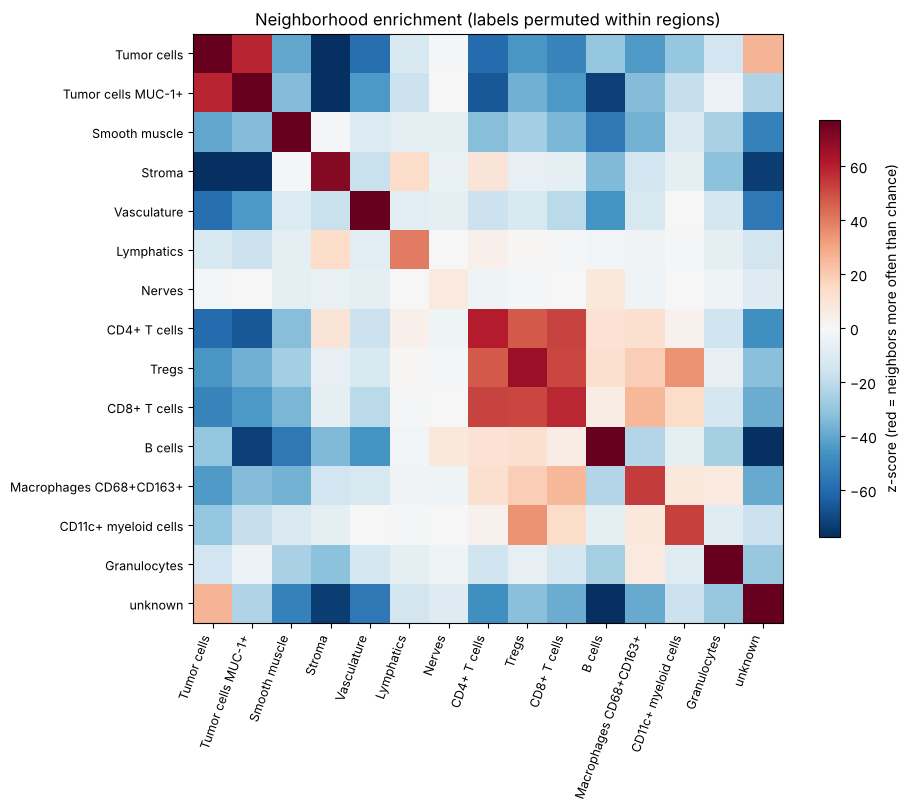

In [31]:
vmax = np.nanpercentile(np.abs(z.values), 95)

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(order)), order, rotation=70, ha="right", fontsize=9)
ax.set_yticks(range(len(order)), order, fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.7, label="z-score (red = neighbors more often than chance)")
ax.set_title("Neighborhood enrichment (labels permuted within regions)")
plt.tight_layout(); plt.savefig(FIG_DIR / "codex_nhood_enrichment.png", dpi=120); plt.show()

In [32]:
# for each type: its strongest neighbor partner (excluding itself), within-region null vs. global null
zz = z.mask(np.eye(len(order), dtype=bool))      # hide the diagonal
partners = pd.DataFrame({"self z": np.diag(z.values).round(0),
                         "top partner": zz.idxmax(axis=1),
                         "partner z": zz.max(axis=1).round(0),
                         "same pair, global-null z": [z_global.loc[t, p].round(0) for t, p in zip(order, zz.idxmax(axis=1))],
                         "self-pair q (within)": [q_perm.loc[t, t] for t in order]},
                        index=order)
partners

,self z,top partner,partner z,"same pair, global-null z",self-pair q (within)
Tumor cells,173.0,Tumor cells MUC-1+,59.0,47.0,0.011056
Tumor cells MUC-1+,138.0,Tumor cells,59.0,47.0,0.011056
Smooth muscle,118.0,Stroma,-1.0,-8.0,0.011056
Stroma,71.0,Lymphatics,14.0,27.0,0.011056
Vasculature,127.0,CD11c+ myeloid cells,-1.0,-7.0,0.011056
Lymphatics,40.0,Stroma,14.0,27.0,0.011056
Nerves,7.0,B cells,8.0,49.0,0.011056
CD4+ T cells,60.0,CD8+ T cells,52.0,75.0,0.011056
Tregs,66.0,CD8+ T cells,52.0,77.0,0.011056
CD8+ T cells,58.0,CD4+ T cells,52.0,75.0,0.011056


**Interpretation notes — regenerate after a clean run.**

Use the fresh composition plot, marker heatmap, and neighborhood-enrichment matrix to evaluate the provisional labels. Do not rely on numeric percentages or z-scores copied from prior saved outputs: those outputs were generated in a different execution state and are cleared in this modified notebook.

- B-cell enrichment in CLR is biologically plausible given the definition of Crohn's-like reaction, but quantify differences at the patient level and report uncertainty.
- CD21-high cells should not automatically be called follicular dendritic cells unless their marker profile and spatial relationship with B-cell follicles support that identity.
- CD138- or CD38-high clusters with epithelial markers such as CDX2, beta-catenin, or cytokeratin need careful review; marker spillover and true co-expression cannot be distinguished by the current summary alone.
- GFAP/Chromogranin A/Synaptophysin-positive clusters should be treated as provisional neural-like profiles until the full marker profile and spatial context support the label.
- `unknown` is intentional for ambiguous or low-coherence clusters, not a claim that those cells are necessarily debris. Its share (section 7b) is not evidence of annotation quality.
- `LOW_SIGNAL`, `MIN_COHER` and the background correction are operational choices; sections 5 (threshold grid) and 7c (background alternatives) show how much the result depends on them.

- Compare the two nulls: pairs that are strong under the global null but weak within regions reflect where cell types occur (which patients and regions), not how they are arranged locally.

Neighborhood enrichment is evidence of spatial association, not causal interaction or definitive cell identity.


## Save

`results/codex_annotated.h5ad` holds my labels (`obs["cell_type"]`), the clusters, the PCA, the coordinates and the
patient metadata. It is the input to notebooks 03 and 04.

In [33]:
adata.write_h5ad(RESULTS_DIR / "codex_annotated.h5ad", compression="gzip")
adata

AnnData object with n_obs × n_vars = 254639 × 56
    obs: 'cell_id', 'patient', 'group', 'region', 'size', 'nuclear', 'leiden_0.4', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0', 'leiden_1.2', 'leiden_1.5', 'cluster', 'cell_type'
    var: 'mean', 'std', 'lineage'
    uns: 'pca', 'neighbors', 'umap', 'leiden_0.4', 'leiden_0.6', 'leiden_0.8', 'leiden_1.0', 'leiden_1.2', 'leiden_1.5', 'cluster_colors', 'group_colors', 'cell_type_colors', 'spatial_neighbors', 'cell_type_nhood_enrichment', 'cell_type_nhood_enrichment_within_region'
    obsm: 'spatial', 'X_pca', 'X_umap', 'spatial_um'
    varm: 'PCs'
    obsp: 'distances', 'connectivities', 'spatial_connectivities', 'spatial_distances'
    layers: None (.X)